# L1 и L2 — влияние штрафа на веса

Посмотрим, как L1 и L2 меняют веса `[3.0, 0.5]` за один шаг. Ошибку данных зададим равной нулю, чтобы выделить действие штрафа.


## Ход работы

Задаём начальные веса `[3.0, 0.5]`, коэффициент штрафа и шаг оптимизатора. Для каждого варианта используем одну и ту же начальную пару: сначала вычисляем L1, затем отдельно L2. Ошибка данных равна нулю, поэтому обновление определяется только выбранным штрафом.

После обратного распространения выполняем один шаг и выводим оба веса. Сравниваем полученные значения с расчётом вручную и показываем их на столбчатой диаграмме. Основное внимание уделяем тому, насколько изменились большой и малый веса при одинаковых настройках.


### Подготавливаем однократное обновление весов

Используем начальные веса `[3.0, 0.5]` и считаем штраф L1 либо L2. Ошибка данных здесь специально равна нулю: мы хотим увидеть чистое действие регуляризации, не смешивая его с обучением по примерам.

In [1]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import torch

def experiment(mode):
    w = torch.nn.Parameter(
        torch.tensor([3.0, 0.5])
    )

    optimizer = torch.optim.SGD([w], lr=0.1)

    optimizer.zero_grad()

    # Для наглядности ошибка предсказания равна нулю
    data_loss = (w * 0).sum()

    if mode == "L1":
        penalty = 0.1 * w.abs().sum()
    else:
        penalty = 0.1 * w.square().sum()

    loss = data_loss + penalty

    loss.backward()
    optimizer.step()

    print(mode, ":", w.detach().tolist())


### Сравниваем обновления L1 и L2

После одного шага напечатаем новые значения обоих весов и построим столбики. `0.49` — второй *вес после обновления*, а не величина штрафа. L1 одинаково сдвигает положительные веса; L2 сильнее сжимает большие по модулю.

L1 : [2.990000009536743, 0.49000000953674316]
L2 : [2.940000057220459, 0.49000000953674316]


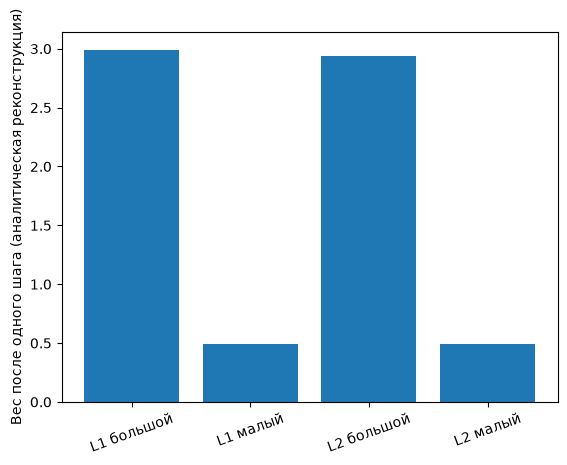

In [2]:


experiment("L1")
experiment("L2")

plt.bar(["L1 большой", "L1 малый", "L2 большой", "L2 малый"],[2.99,0.49,2.94,0.49]); plt.ylabel("Вес после одного шага"); plt.xticks(rotation=20); plt.show()

### Аналитическая проверка одного шага
При lr=0.1 и λ=0.1 получаем:
| Начальный вес | После L1 | После L2 |
|---|---:|---:|
| 3.0 | 2.99 | 2.94 |
| 0.5 | 0.49 | 0.49 |

## Выводы

За один шаг L1 уменьшает оба положительных веса на одинаковую величину. L2 сильнее уменьшает больший вес: из 3 получается 2.94 вместо 2.99 при L1. Вес 0.5 в обоих случаях становится 0.49.


## Полный код


L1 : [2.990000009536743, 0.49000000953674316]
L2 : [2.940000057220459, 0.49000000953674316]


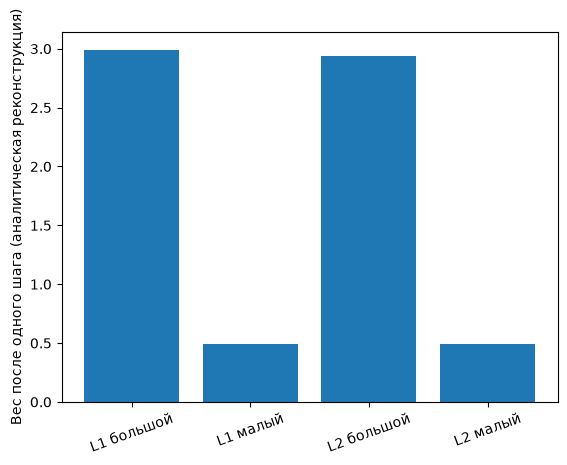

In [3]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import torch

def experiment(mode):
    w = torch.nn.Parameter(
        torch.tensor([3.0, 0.5])
    )

    optimizer = torch.optim.SGD([w], lr=0.1)

    optimizer.zero_grad()

    # Для наглядности ошибка предсказания равна нулю
    data_loss = (w * 0).sum()

    if mode == "L1":
        penalty = 0.1 * w.abs().sum()
    else:
        penalty = 0.1 * w.square().sum()

    loss = data_loss + penalty

    loss.backward()
    optimizer.step()

    print(mode, ":", w.detach().tolist())


experiment("L1")
experiment("L2")

plt.bar(["L1 большой", "L1 малый", "L2 большой", "L2 малый"],[2.99,0.49,2.94,0.49]); plt.ylabel("Вес после одного шага"); plt.xticks(rotation=20); plt.show()